In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

import pandas as pd
from pathlib import Path

def load_dataset():
    BASE_DIR = Path(r"C:\work\Port_Cast_Final")
    FILE_PATH = BASE_DIR / "1.Rawdata_EDA" / "Data" / "port_raw.xlsx"

    return pd.read_excel(FILE_PATH)

In [6]:
d001 = load_dataset()

In [7]:
d001.head(3)

,선박키,입항연도,적재톤수,환적톤수,위험물톤수,총톤수,선박종류명,선박명,출항예정일시,입항일시,...,터미널_출항시각출처,터미널_접안시간,터미널_시간당처리량,터미널_접안시간계산상태,터미널_Shift비율,출항시간차이_분,부산항_입항출항시간차_분,터미널_접안출항시간차_분,접안_부산항입항시간차_분,시간검증상태
0,A8SI6,2020,60500.0,3569.0,0.0,114044,풀컨테이너선,ZIM ANTWERP,2020-01-23 6:00,2020-01-22 12:00,...,예정 출항 대체,21.666667,79.292308,계산완료,0.065288,50,1260,1300,10,정상
1,9713349,2020,50382.0,13581.0,346.0,113042,풀컨테이너선,MOL BEAUTY,2020-01-22 6:00,2020-01-21 3:10,...,예정 출항 대체,35.950000,80.806676,계산완료,0.050964,0,2162,2157,5,정상
2,A8OJ4,2020,6654.0,4802.0,75.0,9610,풀컨테이너선,AS LEONA,2020-01-20 8:00,2020-01-19 14:00,...,예정 출항 대체,18.083333,49.050691,계산완료,0.000000,20,1060,1085,-5,정상


In [15]:
d001.info

<bound method DataFrame.info of            선박키  입항연도     적재톤수     환적톤수   위험물톤수     총톤수   선박종류명  \
0        A8SI6  2020  60500.0   3569.0     0.0  114044  풀컨테이너선   
1      9713349  2020  50382.0  13581.0   346.0  113042  풀컨테이너선   
2        A8OJ4  2020   6654.0   4802.0    75.0    9610  풀컨테이너선   
3        DDYZ2  2020  29540.0   4321.0     0.0   82794  풀컨테이너선   
4         SWWC  2020  80714.0   5151.0     0.0  109149  풀컨테이너선   
...        ...   ...      ...      ...     ...     ...     ...   
36839  9458092  2024  80915.0   6430.0     0.0  141716  풀컨테이너선   
36840  9850836  2024  80159.0    759.0  4529.0  116295  풀컨테이너선   
36841  9604081  2024  25742.0    355.0   231.0   99995  풀컨테이너선   
36842    DSFS5  2024   1073.0    642.0     0.0    3981  풀컨테이너선   
36843  9848766  2024  10100.0      0.0     0.0   26971  풀컨테이너선   

                     선박명            출항예정일시              입항일시  ... 터미널_출항시각출처  \
0            ZIM ANTWERP   2020-01-23 6:00  2020-01-22 12:00  ...   예정 출항 대체   
1             M

In [16]:
# 쉼표가 포함된 문자열도 숫자로 변환
d001["총톤수"] = pd.to_numeric(
    d001["총톤수"].astype("string").str.replace(",", "", regex=False),
    errors="coerce",
)

bins = [
    0, 2000, 5000, 10000, 20000,
    50000, 100000, 150000, float("inf"),
]

labels = [
    "초소형급", "소형급", "중소형급", "중형급",
    "중대형급", "대형급", "초대형급", "급대형급",
]

d001["선박규모"] = pd.cut(
    d001["총톤수"],
    bins=bins,
    labels=labels,
    right=True,  # 각 구간의 상한 포함: 2,000은 초소형급
)

# 구간별 데이터 건수
result = (
    d001.groupby("선박규모", observed=False)
    .size()
    .reset_index(name="건수")
)

print(result)

   선박규모     건수
0  초소형급    130
1   소형급    993
2  중소형급  13638
3   중형급   4601
4  중대형급   5318
5   대형급   6625
6  초대형급   3634
7  급대형급   1905


In [17]:
result = (
    d001.groupby("터미널", observed=False)
    .size()
    .reset_index(name="건수")
)

print(result)

      터미널     건수
0     BCT   2164
1    BNCT   4072
2  BPTC_G   5686
3   BPT_S  10358
4    HPNT   3035
5     PNC   7758
6    PNIT   3771


In [18]:
time_cols = ['입항일시', '터미널_접안일시', '출항일시']

for col in time_cols:
    d001[col] = pd.to_datetime(d001[col])

# 시간 차이: timedelta 형태
d001['재항시간'] = d001['출항일시'] - d001['입항일시']
d001['대기시간'] = d001['터미널_접안일시'] - d001['입항일시']
d001['작업시간'] = d001['출항일시'] - d001['터미널_접안일시']

In [19]:
d001['재항시간_분'] = (
    d001['출항일시'] - d001['입항일시']
).dt.total_seconds() / 60

d001['대기시간_분'] = (
    d001['터미널_접안일시'] - d001['입항일시']
).dt.total_seconds() / 60

d001['작업시간_분'] = (
    d001['출항일시'] - d001['터미널_접안일시']
).dt.total_seconds() / 60

In [20]:
# 선박별 총물동량 계산
cargo_cols = ['터미널_양하수량', '터미널_선적수량', '터미널_Shift수량']
for col in cargo_cols:
    d001[col] = pd.to_numeric(
        d001[col].astype('string').str.replace(',', '', regex=False),
        errors='coerce'
    )
d001['총물동량'] = d001[cargo_cols].sum(axis=1, min_count=1)
d001['재항시간_시간'] = d001['재항시간_분'] / 60

# 터미널별 요약: 물동량과 재항시간 비교
valid = d001.dropna(subset=['터미널', '총물동량', '재항시간_분']).copy()
terminal_analysis = (
    valid.groupby('터미널')
    .agg(
        선박수=('선박키', 'size'),
        총물동량=('총물동량', 'sum'),
        평균물동량=('총물동량', 'mean'),
        중앙물동량=('총물동량', 'median'),
        평균재항시간_분=('재항시간_분', 'mean'),
        중앙재항시간_분=('재항시간_분', 'median'),
        총재항시간_시간=('재항시간_시간', 'sum'),
    )
    .reset_index()
)
terminal_analysis['물동량/재항시간'] = (
    terminal_analysis['총물동량'] / terminal_analysis['총재항시간_시간']
)

# 터미널별 선박 단위 물동량-재항시간 상관계수
correlation = (
    valid.groupby('터미널')
    .apply(lambda g: g['총물동량'].corr(g['재항시간_분']))
    .rename('물동량_재항시간_상관계수')
    .reset_index()
)
terminal_analysis = terminal_analysis.merge(correlation, on='터미널')
terminal_analysis.sort_values('평균재항시간_분')

,터미널,선박수,총물동량,평균물동량,중앙물동량,평균재항시간_분,중앙재항시간_분,총재항시간_시간,물동량/재항시간,물동량_재항시간_상관계수
2,BPTC_G,5686,3493374,614.381639,541.0,1325.473619,996.0,125610.716667,27.811114,0.054078
5,PNC,7758,13736116,1770.574375,1453.5,1531.036607,1310.0,197963.033333,69.387278,0.340697
4,HPNT,3035,5154723,1698.42603,1334.0,1607.798353,1382.0,81327.800000,63.382054,0.408561
3,BPT_S,10358,6296451,607.882892,547.0,1621.712396,1215.0,279961.616667,22.490408,0.074968
0,BCT,2164,1016116,469.554529,197.5,1718.896026,1451.5,61994.850000,16.390329,-0.045462
1,BNCT,4072,6798781,1669.641699,1455.5,1727.505403,1502.5,117240.033333,57.990268,0.333040
6,PNIT,3771,8002997,2122.247945,1930.0,1746.834261,1520.0,109788.533333,72.894653,0.474980


In [21]:
# 재항시간(timedelta)을 시간 단위 숫자로 변환
# 재항시간 = 출항일시 - 입항일시
# 결과 단위: 시간(hour)
d001['재항시간_시간'] = d001['재항시간'].dt.total_seconds() / 3600

# 확인
d001[['입항일시', '출항일시', '재항시간', '재항시간_시간']].head()

,입항일시,출항일시,재항시간,재항시간_시간
0,2020-01-22 12:00:00,2020-01-23 09:00:00,0 days 21:00:00,21.000000
1,2020-01-21 03:10:00,2020-01-22 15:12:00,1 days 12:02:00,36.033333
2,2020-01-19 14:00:00,2020-01-20 07:40:00,0 days 17:40:00,17.666667
3,2020-01-19 22:00:00,2020-01-20 20:00:00,0 days 22:00:00,22.000000
4,2020-01-20 15:00:00,2020-01-21 07:00:00,0 days 16:00:00,16.000000


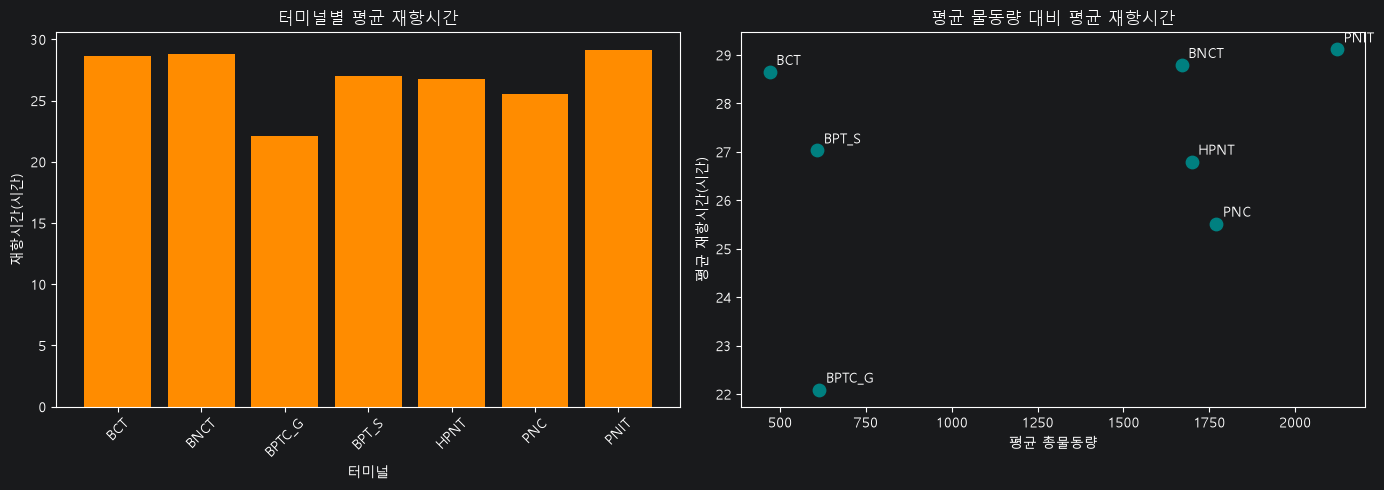

,터미널,평균재항시간_시간,평균물동량
2,BPTC_G,22.091227,614.381639
5,PNC,25.517277,1770.574375
4,HPNT,26.796639,1698.42603
3,BPT_S,27.028540,607.882892
0,BCT,28.648267,469.554529
1,BNCT,28.791757,1669.641699
6,PNIT,29.113904,2122.247945


In [22]:
# 재항시간(시간) 기준 그래프
hourly_terminal = (
    d001.dropna(subset=['터미널', '총물동량', '재항시간_시간'])
    .groupby('터미널')
    .agg(
        평균재항시간_시간=('재항시간_시간', 'mean'),
        평균물동량=('총물동량', 'mean'),
    )
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 터미널별 평균 재항시간
axes[0].bar(
    hourly_terminal['터미널'],
    hourly_terminal['평균재항시간_시간'],
    color='darkorange'
)
axes[0].set_title('터미널별 평균 재항시간')
axes[0].set_xlabel('터미널')
axes[0].set_ylabel('재항시간(시간)')
axes[0].tick_params(axis='x', rotation=45)

# 평균 물동량과 평균 재항시간 비교
axes[1].scatter(
    hourly_terminal['평균물동량'],
    hourly_terminal['평균재항시간_시간'],
    s=80,
    color='teal'
)
for _, row in hourly_terminal.iterrows():
    axes[1].annotate(
        row['터미널'],
        (row['평균물동량'], row['평균재항시간_시간']),
        xytext=(5, 5),
        textcoords='offset points'
    )
axes[1].set_title('평균 물동량 대비 평균 재항시간')
axes[1].set_xlabel('평균 총물동량')
axes[1].set_ylabel('평균 재항시간(시간)')

plt.tight_layout()
plt.show()

hourly_terminal.sort_values('평균재항시간_시간')

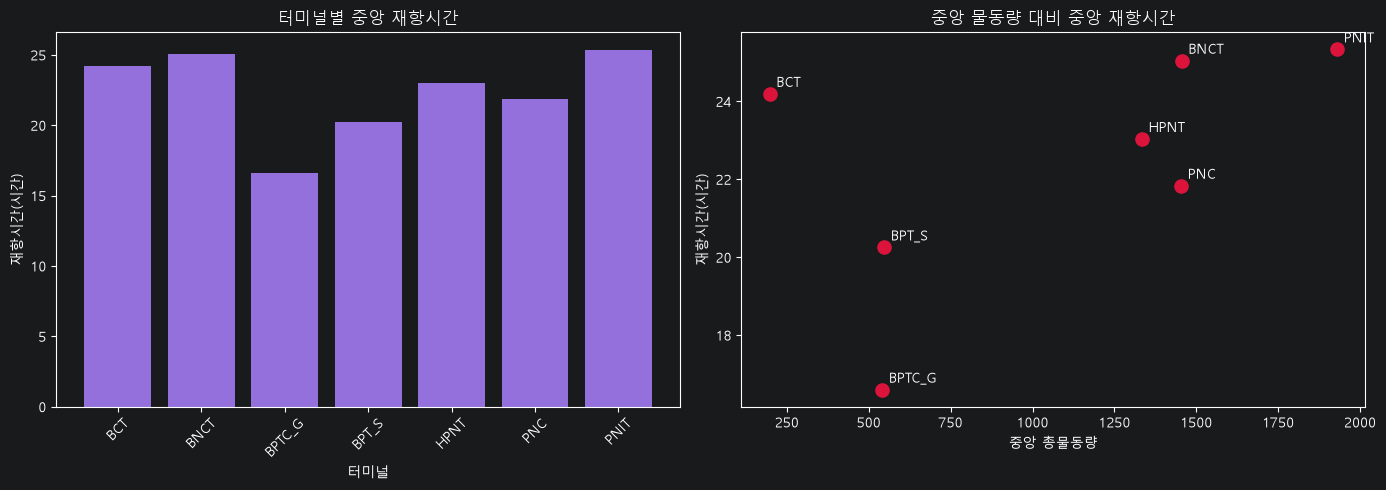

,터미널,중앙재항시간_시간,중앙물동량
2,BPTC_G,16.600000,541.0
3,BPT_S,20.250000,547.0
5,PNC,21.833333,1453.5
4,HPNT,23.033333,1334.0
0,BCT,24.191667,197.5
1,BNCT,25.041667,1455.5
6,PNIT,25.333333,1930.0


In [23]:
# 중앙값 기준 터미널별 분석 및 그래프
median_terminal = (
    d001.dropna(subset=['터미널', '총물동량', '재항시간_시간'])
    .groupby('터미널')
    .agg(
        중앙재항시간_시간=('재항시간_시간', 'median'),
        중앙물동량=('총물동량', 'median'),
    )
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 터미널별 중앙 재항시간
axes[0].bar(
    median_terminal['터미널'],
    median_terminal['중앙재항시간_시간'],
    color='mediumpurple'
)
axes[0].set_title('터미널별 중앙 재항시간')
axes[0].set_xlabel('터미널')
axes[0].set_ylabel('재항시간(시간)')
axes[0].tick_params(axis='x', rotation=45)

# 중앙 물동량 대비 중앙 재항시간
axes[1].scatter(
    median_terminal['중앙물동량'],
    median_terminal['중앙재항시간_시간'],
    s=90,
    color='crimson'
)
for _, row in median_terminal.iterrows():
    axes[1].annotate(
        row['터미널'],
        (row['중앙물동량'], row['중앙재항시간_시간']),
        xytext=(5, 5),
        textcoords='offset points'
    )
axes[1].set_title('중앙 물동량 대비 중앙 재항시간')
axes[1].set_xlabel('중앙 총물동량')
axes[1].set_ylabel('재항시간(시간)')

plt.tight_layout()
plt.show()

median_terminal.sort_values('중앙재항시간_시간')

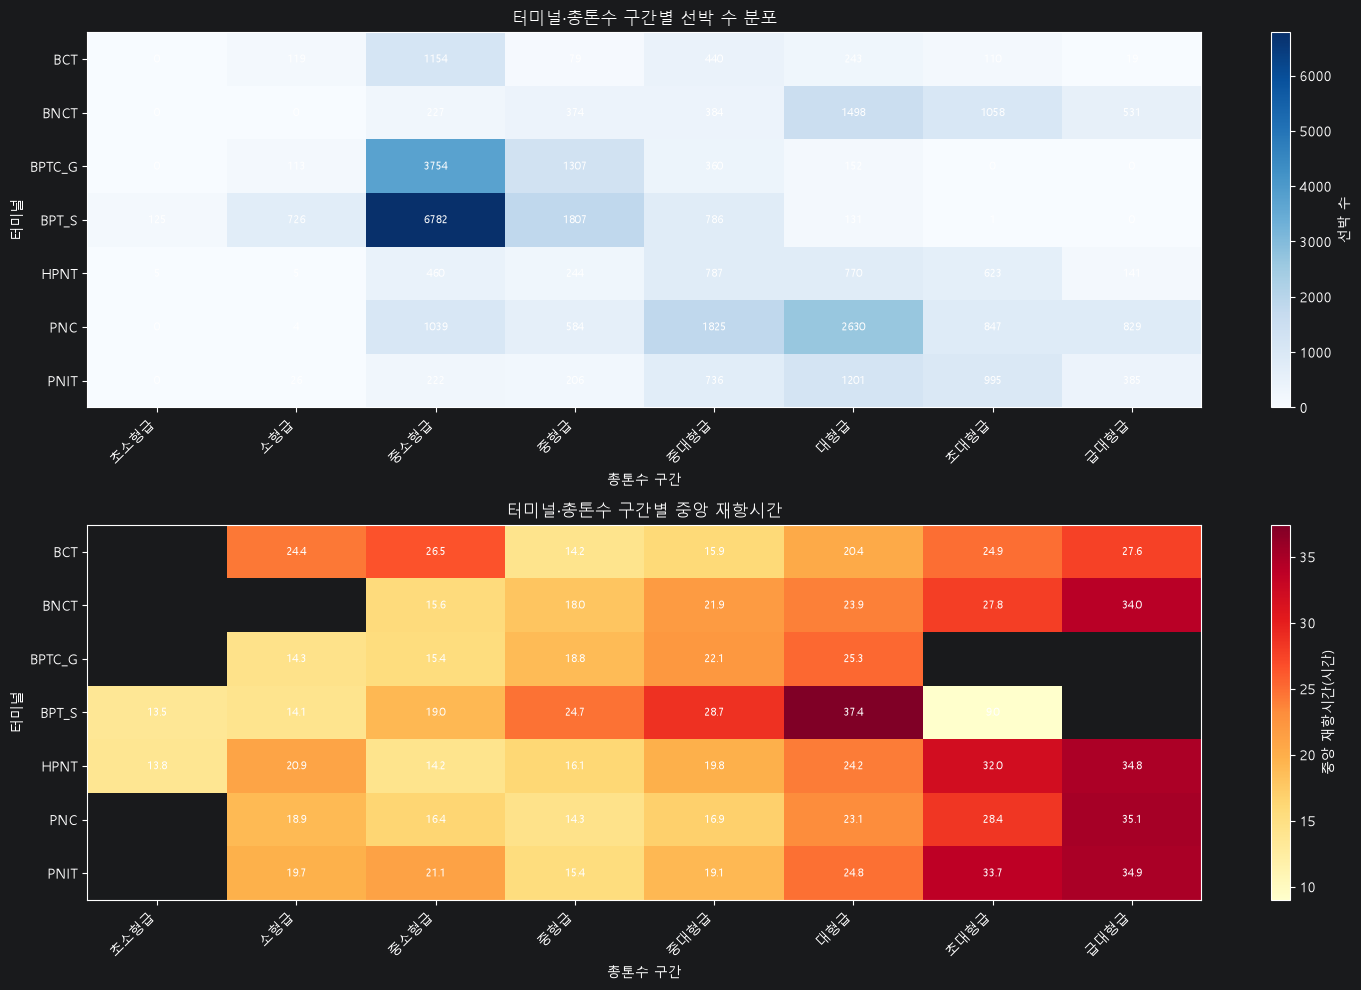

,터미널,선박규모,선박수,중앙재항시간_시간,평균재항시간_시간,중앙총톤수
0,BCT,초소형급,0,NaN,NaN,<NA>
1,BCT,소형급,119,24.400000,32.495518,3736.0
2,BCT,중소형급,1154,26.466667,30.144411,7545.0
3,BCT,중형급,79,14.216667,19.481857,18670.0
4,BCT,중대형급,440,15.916667,24.907462,40774.0
5,BCT,대형급,243,20.416667,26.858848,73157.0
6,BCT,초대형급,110,24.891667,33.766061,116295.0
7,BCT,급대형급,19,27.633333,31.679825,155492.0
8,BNCT,초소형급,0,NaN,NaN,<NA>
9,BNCT,소형급,0,NaN,NaN,<NA>


In [24]:
# 동일 터미널·동일 총톤수 구간별 분포
# 기존에 만든 선박규모 구간을 사용합니다.
analysis_dist = d001.dropna(
    subset=['터미널', '선박규모', '총톤수', '재항시간_시간']
).copy()

# 구간 순서 유지
size_order = list(d001['선박규모'].cat.categories)
terminal_order = sorted(analysis_dist['터미널'].unique())

# 터미널·총톤수 구간별 요약
size_summary = (
    analysis_dist.groupby(['터미널', '선박규모'], observed=False)
    .agg(
        선박수=('선박키', 'size'),
        중앙재항시간_시간=('재항시간_시간', 'median'),
        평균재항시간_시간=('재항시간_시간', 'mean'),
        중앙총톤수=('총톤수', 'median'),
    )
    .reset_index()
)

# 선박 수 분포와 중앙 재항시간을 각각 행렬로 변환
count_pivot = size_summary.pivot(
    index='터미널', columns='선박규모', values='선박수'
).reindex(index=terminal_order, columns=size_order)
median_pivot = size_summary.pivot(
    index='터미널', columns='선박규모', values='중앙재항시간_시간'
).reindex(index=terminal_order, columns=size_order)

fig, axes = plt.subplots(2, 1, figsize=(15, 10))

im1 = axes[0].imshow(count_pivot, aspect='auto', cmap='Blues')
axes[0].set_title('터미널·총톤수 구간별 선박 수 분포')
axes[0].set_xlabel('총톤수 구간')
axes[0].set_ylabel('터미널')
axes[0].set_xticks(range(len(size_order)), size_order, rotation=45, ha='right')
axes[0].set_yticks(range(len(terminal_order)), terminal_order)
fig.colorbar(im1, ax=axes[0], label='선박 수')

im2 = axes[1].imshow(median_pivot, aspect='auto', cmap='YlOrRd')
axes[1].set_title('터미널·총톤수 구간별 중앙 재항시간')
axes[1].set_xlabel('총톤수 구간')
axes[1].set_ylabel('터미널')
axes[1].set_xticks(range(len(size_order)), size_order, rotation=45, ha='right')
axes[1].set_yticks(range(len(terminal_order)), terminal_order)
fig.colorbar(im2, ax=axes[1], label='중앙 재항시간(시간)')

# 각 칸에 값 표시
for ax, matrix, fmt in [
    (axes[0], count_pivot, '.0f'),
    (axes[1], median_pivot, '.1f'),
]:
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            value = matrix.iloc[i, j]
            if pd.notna(value):
                ax.text(j, i, format(value, fmt), ha='center', va='center', fontsize=8)

plt.tight_layout()
plt.show()

size_summary.sort_values(['터미널', '선박규모'])

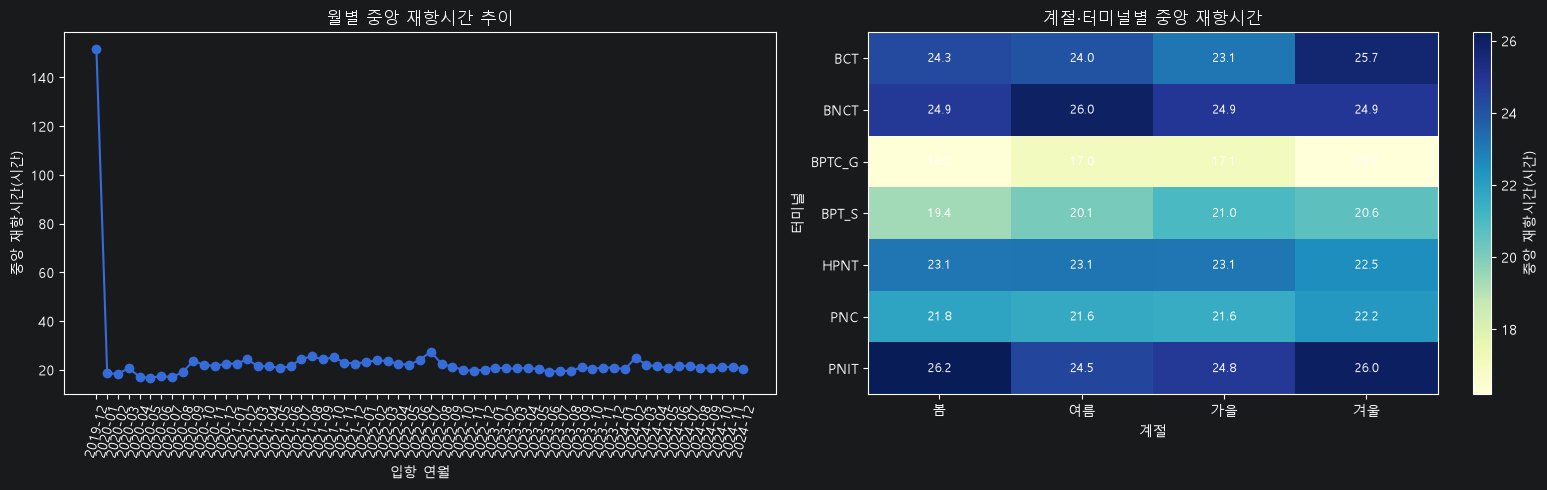

,계절,선박수,중앙재항시간_시간,평균재항시간_시간,중앙물동량
0,봄,9488,20.841667,25.402721,770.0
1,여름,9334,21.250000,26.635226,743.0
2,가을,9146,21.450000,26.714252,769.0
3,겨울,8876,21.275000,27.030624,752.0


In [25]:
# 계절성 분석: 입항일 기준
season_data = d001.dropna(
    subset=['입항일시', '터미널', '재항시간_시간', '총물동량']
).copy()
season_data['입항연도'] = season_data['입항일시'].dt.year
season_data['입항월'] = season_data['입항일시'].dt.month
season_data['연월'] = season_data['입항일시'].dt.to_period('M').astype(str)

season_map = {
    12: '겨울', 1: '겨울', 2: '겨울',
    3: '봄', 4: '봄', 5: '봄',
    6: '여름', 7: '여름', 8: '여름',
    9: '가을', 10: '가을', 11: '가을',
}
season_order = ['봄', '여름', '가을', '겨울']
season_data['계절'] = season_data['입항월'].map(season_map)
season_data['계절'] = pd.Categorical(
    season_data['계절'], categories=season_order, ordered=True
)

# 계절별 요약
season_summary = (
    season_data.groupby('계절', observed=False)
    .agg(
        선박수=('선박키', 'size'),
        중앙재항시간_시간=('재항시간_시간', 'median'),
        평균재항시간_시간=('재항시간_시간', 'mean'),
        중앙물동량=('총물동량', 'median'),
    )
    .reset_index()
)

# 월별 중앙 재항시간 추이
monthly_summary = (
    season_data.groupby('연월', sort=True)
    .agg(
        선박수=('선박키', 'size'),
        중앙재항시간_시간=('재항시간_시간', 'median'),
        평균재항시간_시간=('재항시간_시간', 'mean'),
    )
    .reset_index()
)

# 계절·터미널별 중앙 재항시간
season_terminal = (
    season_data.groupby(['터미널', '계절'], observed=False)
    .agg(중앙재항시간_시간=('재항시간_시간', 'median'))
    .reset_index()
)
season_terminal_pivot = season_terminal.pivot(
    index='터미널', columns='계절', values='중앙재항시간_시간'
).reindex(columns=season_order)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 월별 계절성 추이
axes[0].plot(
    monthly_summary['연월'],
    monthly_summary['중앙재항시간_시간'],
    marker='o',
    linewidth=1.5,
)
axes[0].set_title('월별 중앙 재항시간 추이')
axes[0].set_xlabel('입항 연월')
axes[0].set_ylabel('중앙 재항시간(시간)')
axes[0].tick_params(axis='x', rotation=75)

# 계절·터미널별 중앙값 히트맵
im = axes[1].imshow(season_terminal_pivot, aspect='auto', cmap='YlGnBu')
axes[1].set_title('계절·터미널별 중앙 재항시간')
axes[1].set_xlabel('계절')
axes[1].set_ylabel('터미널')
axes[1].set_xticks(range(len(season_order)), season_order)
axes[1].set_yticks(range(len(season_terminal_pivot.index)), season_terminal_pivot.index)
fig.colorbar(im, ax=axes[1], label='중앙 재항시간(시간)')

for i in range(season_terminal_pivot.shape[0]):
    for j in range(season_terminal_pivot.shape[1]):
        value = season_terminal_pivot.iloc[i, j]
        if pd.notna(value):
            axes[1].text(j, i, f'{value:.1f}', ha='center', va='center', fontsize=9)

plt.tight_layout()
plt.show()

season_summary

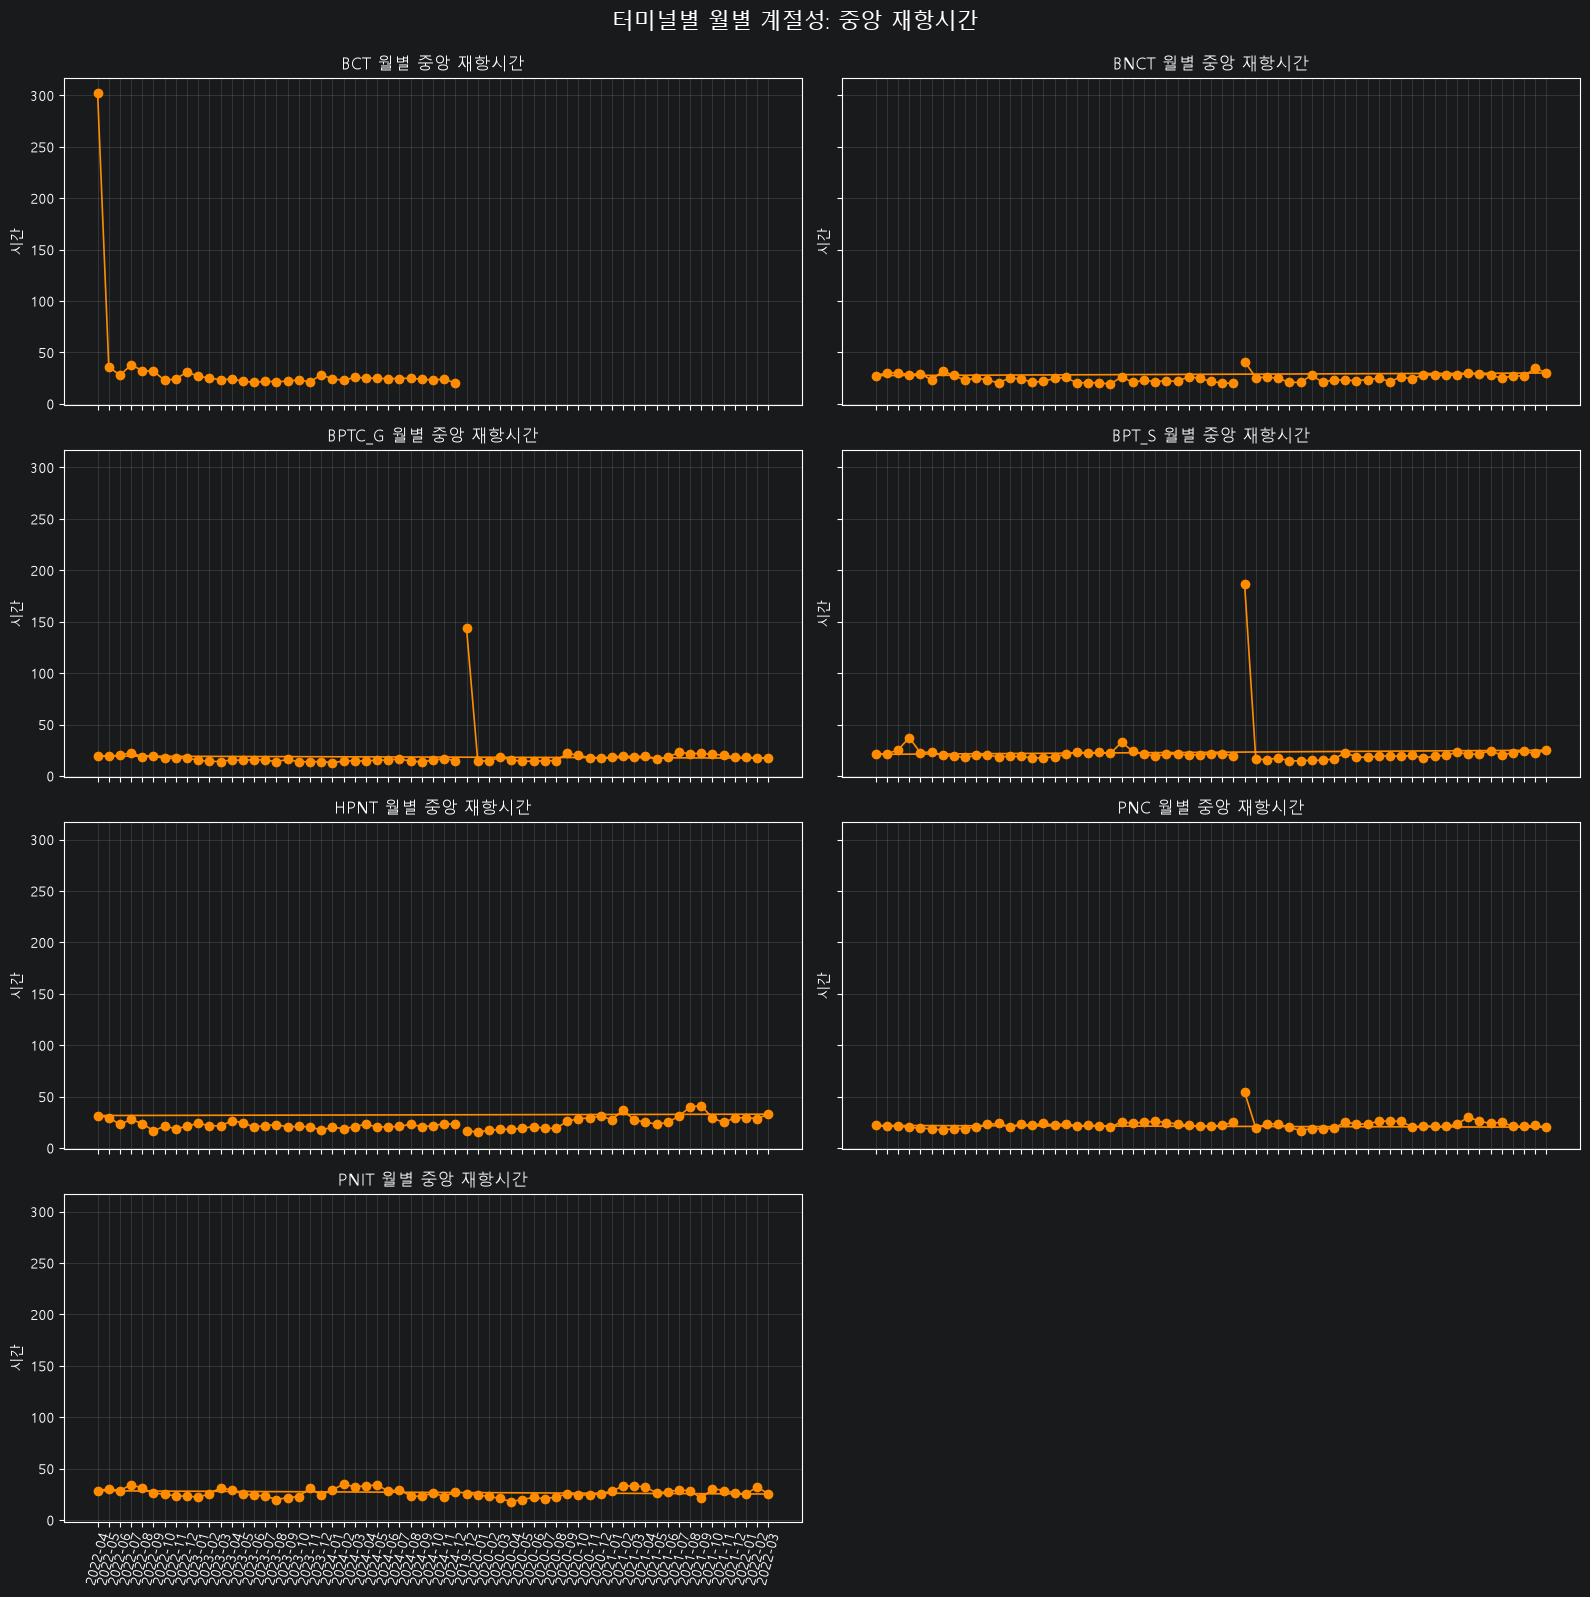

계절,봄,여름,가을,겨울
터미널,,,,
BCT,24.300000,24.000000,23.133333,25.716667
BNCT,24.858333,25.991667,24.866667,24.883333
BPTC_G,16.250000,17.000000,17.050000,16.200000
BPT_S,19.350000,20.091667,21.000000,20.650000
HPNT,23.125000,23.150000,23.116667,22.533333
PNC,21.825000,21.633333,21.566667,22.216667
PNIT,26.233333,24.466667,24.816667,26.000000


In [26]:
# 터미널별 계절성 분석
terminal_monthly = (
    season_data.groupby(['터미널', '연월'], sort=True)
    .agg(
        중앙재항시간_시간=('재항시간_시간', 'median'),
        선박수=('선박키', 'size'),
    )
    .reset_index()
)

terminals = sorted(terminal_monthly['터미널'].unique())
fig, axes = plt.subplots(4, 2, figsize=(16, 16), sharex=True, sharey=True)
axes = axes.flatten()

for ax, terminal in zip(axes, terminals):
    subset = terminal_monthly[terminal_monthly['터미널'] == terminal]
    ax.plot(
        subset['연월'],
        subset['중앙재항시간_시간'],
        marker='o',
        linewidth=1.2,
        color='darkorange',
    )
    ax.set_title(f'{terminal} 월별 중앙 재항시간')
    ax.set_ylabel('시간')
    ax.tick_params(axis='x', rotation=75)
    ax.grid(alpha=0.25)

# 남는 패널 숨기기
for ax in axes[len(terminals):]:
    ax.set_visible(False)

fig.suptitle('터미널별 월별 계절성: 중앙 재항시간', fontsize=16, y=0.995)
plt.tight_layout()
plt.show()

# 터미널별 계절 중앙값 표
terminal_season_summary = (
    season_data.groupby(['터미널', '계절'], observed=False)
    .agg(
        선박수=('선박키', 'size'),
        중앙재항시간_시간=('재항시간_시간', 'median'),
        중앙물동량=('총물동량', 'median'),
    )
    .reset_index()
)

terminal_season_pivot = terminal_season_summary.pivot(
    index='터미널', columns='계절', values='중앙재항시간_시간'
).reindex(columns=season_order)

terminal_season_pivot

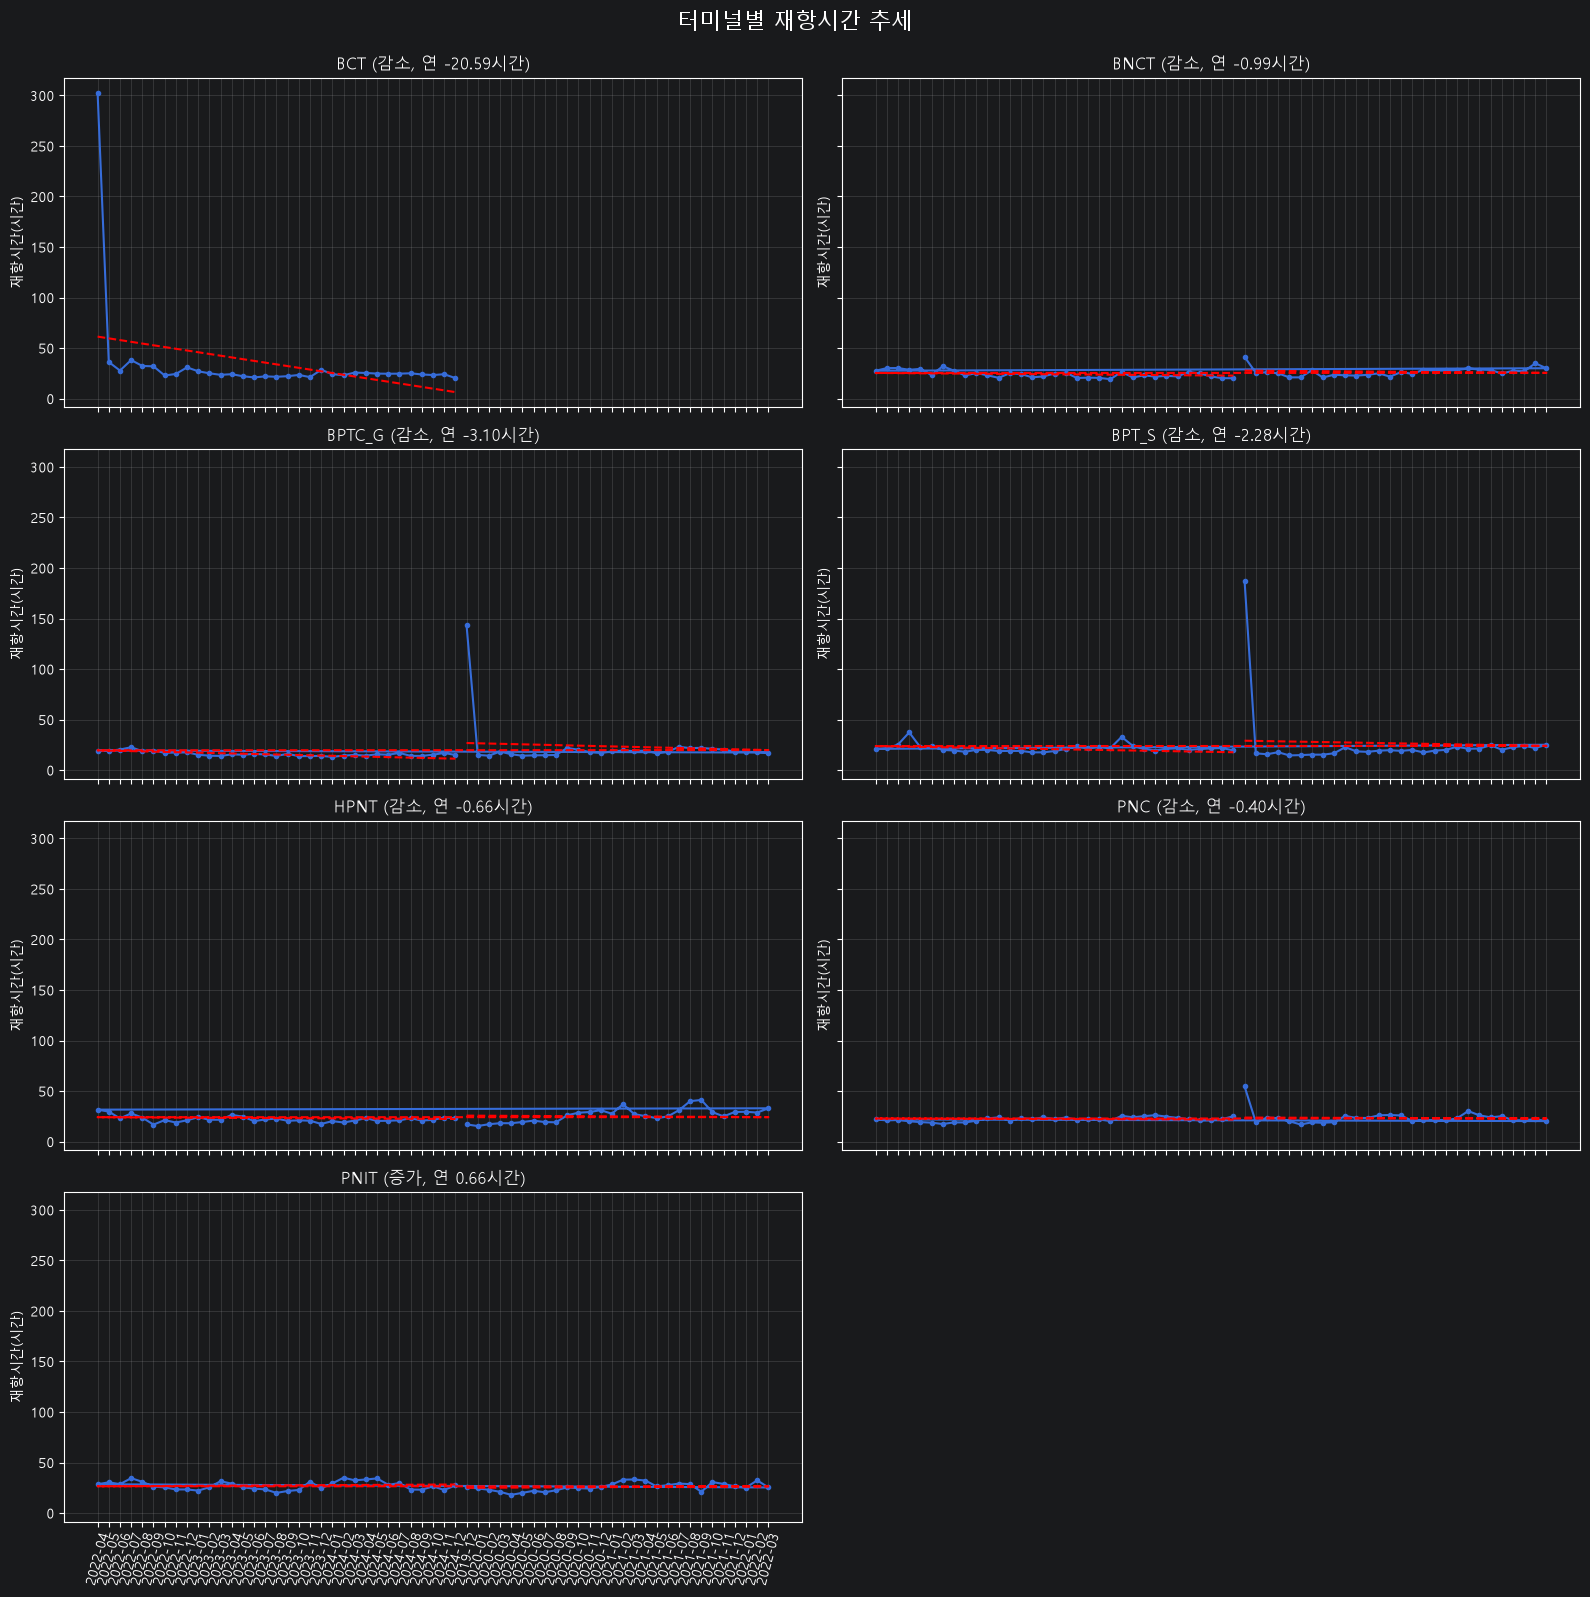

,터미널,분석월수,월별변화량_시간,연간변화량_시간,추세방향,R2
0,BCT,33,-1.715639,-20.587667,감소,0.117317
2,BPTC_G,61,-0.258432,-3.101190,감소,0.078029
3,BPT_S,61,-0.189963,-2.279561,감소,0.024408
1,BNCT,61,-0.082441,-0.989286,감소,0.132089
4,HPNT,61,-0.055290,-0.663480,감소,0.031791
5,PNC,61,-0.032980,-0.395759,감소,0.014608
6,PNIT,61,0.055185,0.662221,증가,0.055621


In [27]:
# 터미널별 추세 분석
trend_monthly = (
    season_data.groupby(['터미널', '연월'], sort=True)
    .agg(
        중앙재항시간_시간=('재항시간_시간', 'median'),
        중앙물동량=('총물동량', 'median'),
        선박수=('선박키', 'size'),
    )
    .reset_index()
)
trend_monthly['기간순번'] = (
    pd.to_datetime(trend_monthly['연월']).dt.year * 12
    + pd.to_datetime(trend_monthly['연월']).dt.month
)

trend_results = []
for terminal, group in trend_monthly.groupby('터미널'):
    group = group.dropna(subset=['기간순번', '중앙재항시간_시간']).sort_values('기간순번')
    x = group['기간순번'].to_numpy()
    y = group['중앙재항시간_시간'].to_numpy()
    slope, intercept = np.polyfit(x, y, 1)
    predicted = slope * x + intercept
    ss_res = np.sum((y - predicted) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot else np.nan
    trend_results.append({
        '터미널': terminal,
        '분석월수': len(group),
        '월별변화량_시간': slope,
        '연간변화량_시간': slope * 12,
        '추세방향': '증가' if slope > 0 else '감소' if slope < 0 else '변화없음',
        'R2': r2,
    })

trend_results = pd.DataFrame(trend_results).sort_values('연간변화량_시간')

# 터미널별 월별 중앙 재항시간과 선형 추세선
terminals = sorted(trend_monthly['터미널'].unique())
fig, axes = plt.subplots(4, 2, figsize=(16, 16), sharex=True, sharey=True)
axes = axes.flatten()

for ax, terminal in zip(axes, terminals):
    group = trend_monthly[
        trend_monthly['터미널'] == terminal
    ].dropna(subset=['중앙재항시간_시간']).sort_values('기간순번')
    result = trend_results[trend_results['터미널'] == terminal].iloc[0]
    x = group['기간순번'].to_numpy()
    y = group['중앙재항시간_시간'].to_numpy()
    ax.plot(group['연월'], y, marker='o', markersize=3, label='월별 중앙값')
    ax.plot(
        group['연월'],
        result['월별변화량_시간'] * x + (y.mean() - result['월별변화량_시간'] * x.mean()),
        linestyle='--',
        color='red',
        label='선형 추세',
    )
    ax.set_title(f"{terminal} ({result['추세방향']}, 연 {result['연간변화량_시간']:.2f}시간)")
    ax.set_ylabel('재항시간(시간)')
    ax.tick_params(axis='x', rotation=75)
    ax.grid(alpha=0.25)

for ax in axes[len(terminals):]:
    ax.set_visible(False)

fig.suptitle('터미널별 재항시간 추세', fontsize=16, y=0.995)
plt.tight_layout()
plt.show()

trend_results

IQR 기준 이상 월


,터미널,연월,선박수,중앙재항시간_시간,하한기준,상한기준
0,BCT,2022-04,2,302.666667,17.237500,32.870833
1,BCT,2022-05,4,36.191667,17.237500,32.870833
2,BCT,2022-07,20,38.100000,17.237500,32.870833
3,BNCT,2019-12,3,41.216667,13.341667,36.341667
4,BPTC_G,2019-12,3,143.650000,9.158333,24.558333
5,BPT_S,2019-12,12,186.716667,14.104167,26.737500
6,BPT_S,2022-07,163,37.300000,14.104167,26.737500
7,BPT_S,2024-02,167,32.816667,14.104167,26.737500
8,HPNT,2021-08,37,39.983333,10.062500,38.029167
9,HPNT,2021-09,38,41.183333,10.062500,38.029167


터미널별 재항시간 상위 3개 월


,터미널,연월,선박수,중앙재항시간_시간
0,BCT,2022-04,2,302.666667
3,BCT,2022-07,20,38.100000
1,BCT,2022-05,4,36.191667
33,BNCT,2019-12,3,41.216667
59,BNCT,2022-02,57,34.916667
67,BNCT,2022-10,63,32.066667
94,BPTC_G,2019-12,3,143.650000
113,BPTC_G,2021-07,91,23.000000
125,BPTC_G,2022-07,93,22.583333
155,BPT_S,2019-12,12,186.716667


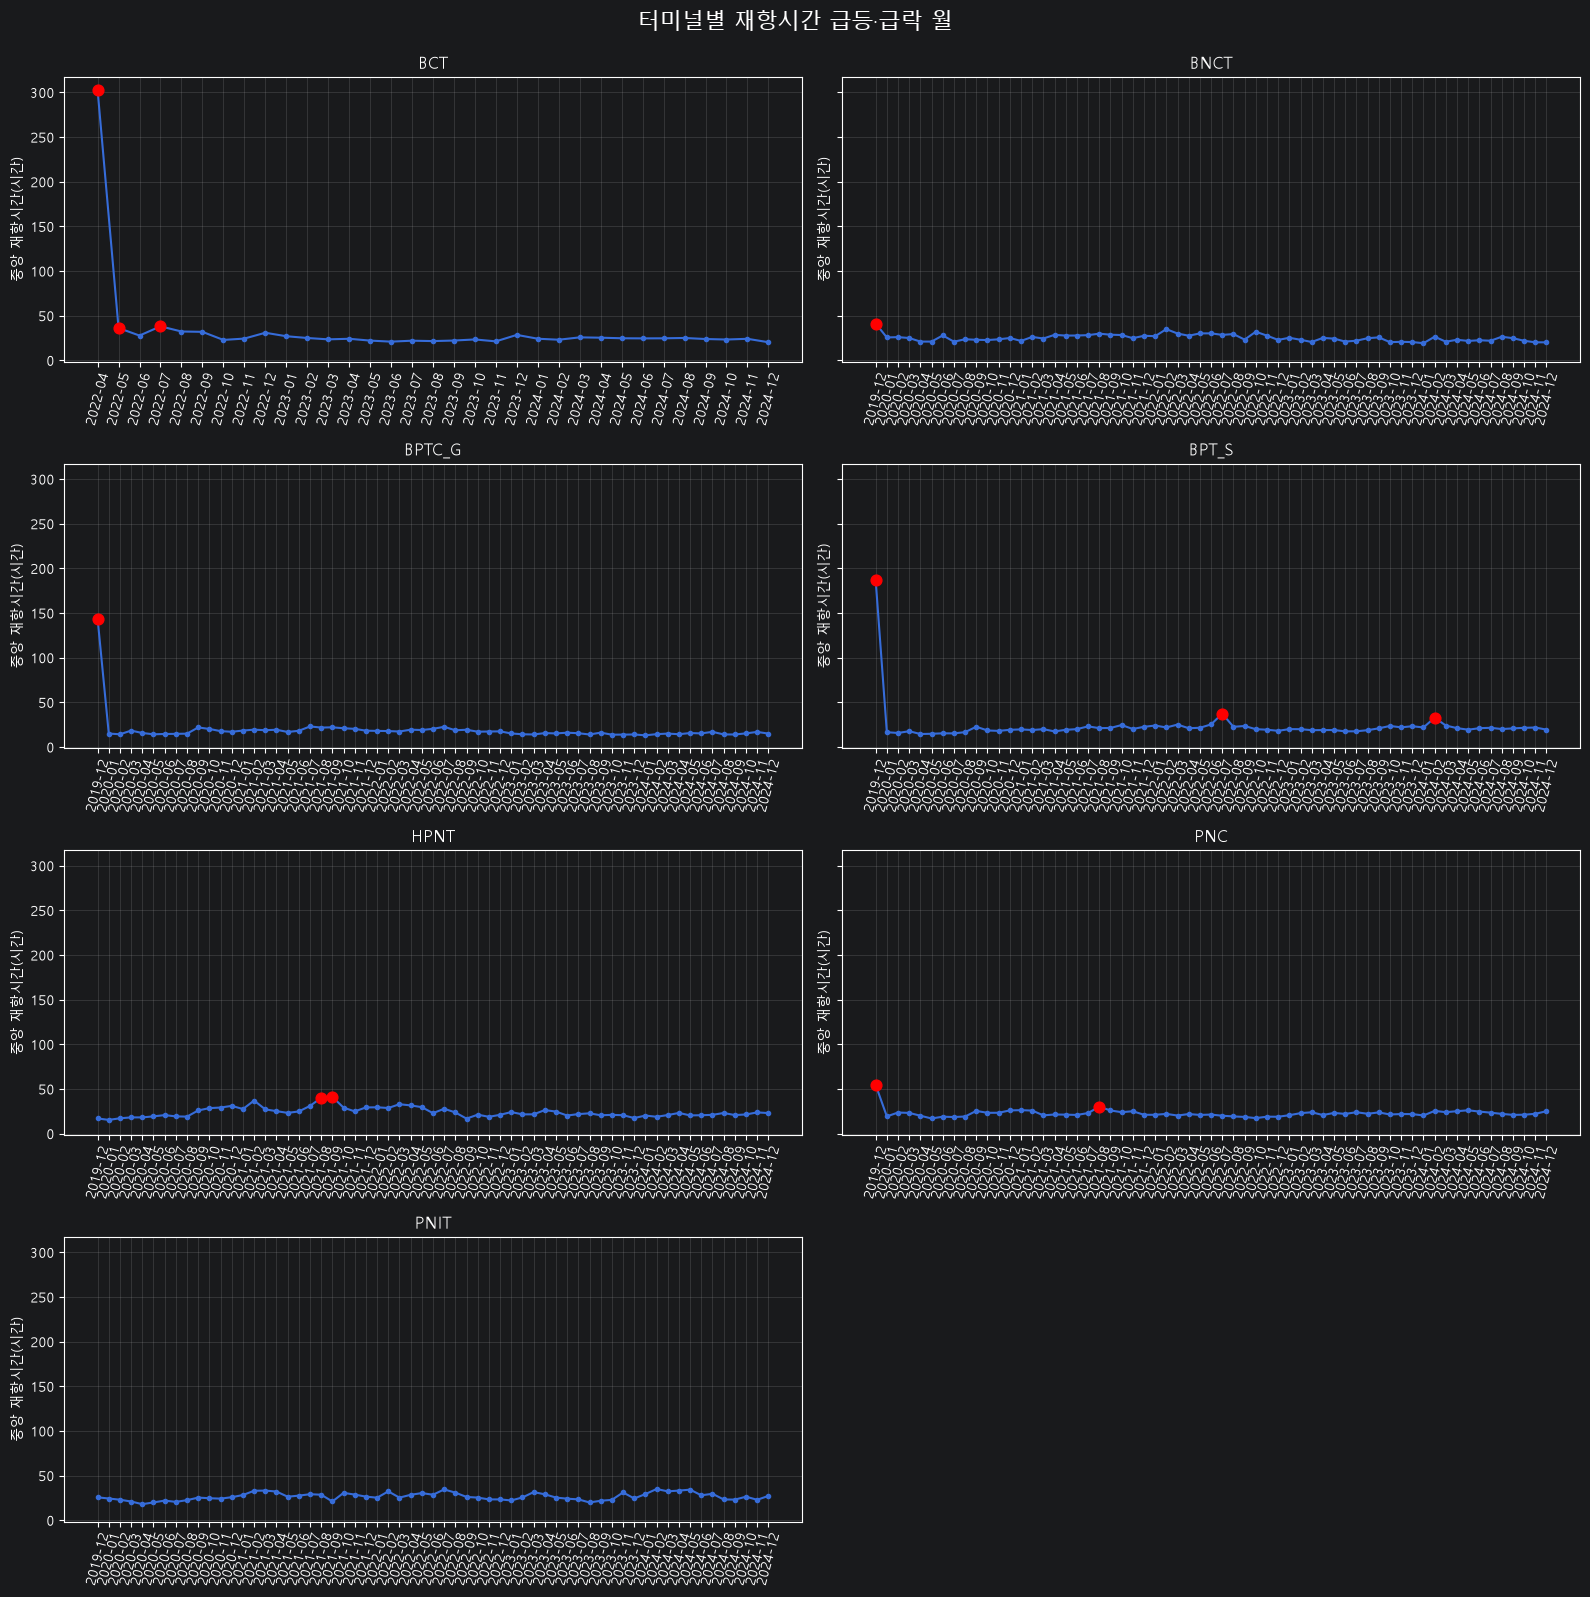

In [28]:
# 터미널별 재항시간 추세의 급등·급락 월 확인
# 기준: 터미널별 월별 중앙 재항시간의 IQR 밖인 월
outlier_rows = []
for terminal, group in trend_monthly.groupby('터미널'):
    group = group.dropna(subset=['중앙재항시간_시간']).copy()
    q1 = group['중앙재항시간_시간'].quantile(0.25)
    q3 = group['중앙재항시간_시간'].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = group[
        (group['중앙재항시간_시간'] < lower)
        | (group['중앙재항시간_시간'] > upper)
    ].copy()
    outliers['하한기준'] = lower
    outliers['상한기준'] = upper
    outlier_rows.append(outliers)

outlier_table = pd.concat(outlier_rows, ignore_index=True) if outlier_rows else pd.DataFrame()
outlier_table = outlier_table[
    ['터미널', '연월', '선박수', '중앙재항시간_시간', '하한기준', '상한기준']
].sort_values(['터미널', '연월'])

print('IQR 기준 이상 월')
display(outlier_table)

# 터미널별로 재항시간이 가장 길었던 월도 함께 확인
peak_table = (
    trend_monthly.sort_values(
        ['터미널', '중앙재항시간_시간'], ascending=[True, False]
    )
    .groupby('터미널', as_index=False)
    .head(3)
    [['터미널', '연월', '선박수', '중앙재항시간_시간']]
)
print('터미널별 재항시간 상위 3개 월')
display(peak_table)

# 이상 월을 그래프에 표시
fig, axes = plt.subplots(4, 2, figsize=(16, 16), sharey=True)
axes = axes.flatten()

for ax, terminal in zip(axes, sorted(trend_monthly['터미널'].unique())):
    group = trend_monthly[
        trend_monthly['터미널'] == terminal
    ].dropna(subset=['중앙재항시간_시간']).sort_values('연월')
    outliers = outlier_table[outlier_table['터미널'] == terminal]
    ax.plot(group['연월'], group['중앙재항시간_시간'], marker='o', markersize=3)
    if not outliers.empty:
        ax.scatter(
            outliers['연월'],
            outliers['중앙재항시간_시간'],
            color='red',
            s=60,
            zorder=3,
            label='IQR 이상치',
        )
    ax.set_title(terminal)
    ax.set_ylabel('중앙 재항시간(시간)')
    ax.tick_params(axis='x', rotation=75)
    ax.grid(alpha=0.25)

for ax in axes[len(trend_monthly['터미널'].unique()):]:
    ax.set_visible(False)

fig.suptitle('터미널별 재항시간 급등·급락 월', fontsize=16, y=0.995)
plt.tight_layout()
plt.show()